In [ ]:
# ==========================================
# PROJECT: Automatic Modulation Classification
# Step 1: Import Libraries
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# ==========================================
# Upload Dataset
# ==========================================

from google.colab import files

uploaded = files.upload()

Saving Synthetic_LowSNR_IQ_Dataset_50000.xlsx to Synthetic_LowSNR_IQ_Dataset_50000.xlsx


In [ ]:
# ==========================================
# Load Dataset
# ==========================================

file_name = "Synthetic_LowSNR_IQ_Dataset_50000.xlsx"

df = pd.read_excel(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (50000, 259)


In [ ]:
# Display first 5 rows

df.head()

,Signal_ID,Modulation,SNR_dB,I_1,I_2,I_3,I_4,I_5,I_6,I_7,...,Q_119,Q_120,Q_121,Q_122,Q_123,Q_124,Q_125,Q_126,Q_127,Q_128
0,1,BPSK,-20,0.150838,5.145218,6.029131,4.609812,-3.465859,-2.269321,5.066806,...,4.119995,12.249293,8.325559,3.104812,12.331479,3.104150,5.854761,-2.097073,0.470550,-4.931531
1,2,QPSK,-16,1.188420,5.135509,-6.441442,-4.877170,-7.851276,-4.250179,1.254350,...,-1.129435,5.372381,-5.349725,-11.471828,7.894370,12.081041,-1.101019,-9.348391,-0.678131,-1.984103
2,3,8PSK,-12,-3.202535,-5.824795,-2.712683,-1.869097,-1.273225,4.133047,-1.396963,...,1.495237,1.381529,2.671807,1.521665,-0.294199,0.945408,-8.956855,0.370733,-10.977545,-4.851623
3,4,16QAM,-8,5.982769,-2.035003,3.542467,1.426073,0.062401,0.437320,0.441017,...,-3.769078,0.075293,1.387344,1.513428,-3.153198,-1.213034,2.311098,-4.328758,-2.902096,1.225850
4,5,64QAM,-4,0.316131,-0.964673,-1.719846,1.278235,0.955251,1.113382,-2.204694,...,-0.660773,0.748992,0.385571,0.579307,0.111972,-2.092564,0.260523,-0.584655,-1.287513,0.599704


In [ ]:
# ==========================================
# Dataset Information
# ==========================================

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 50000
Number of columns: 259

Column names:
['Signal_ID', 'Modulation', 'SNR_dB', 'I_1', 'I_2', 'I_3', 'I_4', 'I_5', 'I_6', 'I_7', 'I_8', 'I_9', 'I_10', 'I_11', 'I_12', 'I_13', 'I_14', 'I_15', 'I_16', 'I_17', 'I_18', 'I_19', 'I_20', 'I_21', 'I_22', 'I_23', 'I_24', 'I_25', 'I_26', 'I_27', 'I_28', 'I_29', 'I_30', 'I_31', 'I_32', 'I_33', 'I_34', 'I_35', 'I_36', 'I_37', 'I_38', 'I_39', 'I_40', 'I_41', 'I_42', 'I_43', 'I_44', 'I_45', 'I_46', 'I_47', 'I_48', 'I_49', 'I_50', 'I_51', 'I_52', 'I_53', 'I_54', 'I_55', 'I_56', 'I_57', 'I_58', 'I_59', 'I_60', 'I_61', 'I_62', 'I_63', 'I_64', 'I_65', 'I_66', 'I_67', 'I_68', 'I_69', 'I_70', 'I_71', 'I_72', 'I_73', 'I_74', 'I_75', 'I_76', 'I_77', 'I_78', 'I_79', 'I_80', 'I_81', 'I_82', 'I_83', 'I_84', 'I_85', 'I_86', 'I_87', 'I_88', 'I_89', 'I_90', 'I_91', 'I_92', 'I_93', 'I_94', 'I_95', 'I_96', 'I_97', 'I_98', 'I_99', 'I_100', 'I_101', 'I_102', 'I_103', 'I_104', 'I_105', 'I_106', 'I_107', 'I_108', 'I_109', 'I_110', 'I_111', 'I_112', 'I

In [ ]:
# ==========================================
# Check Missing Values
# ==========================================

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

if missing_values.sum() == 0:
    print("✓ No missing values found!")
else:
    print("⚠ Missing values found!")
    print(missing_values[missing_values > 0])

Total missing values: 0
✓ No missing values found!


In [ ]:
# ==========================================
# Modulation Class Distribution
# ==========================================

print(df["Modulation"].value_counts())

Modulation
BPSK      5000
QPSK      5000
8PSK      5000
16QAM     5000
64QAM     5000
GMSK      5000
OOK       5000
4ASK      5000
AM-DSB    5000
FM        5000
Name: count, dtype: int64


In [ ]:
# ==========================================
# SNR Distribution
# ==========================================

print("SNR values:")
print(sorted(df["SNR_dB"].unique()))

print("\nSNR distribution:")
print(df["SNR_dB"].value_counts().sort_index())

SNR values:
[np.int64(-20), np.int64(-16), np.int64(-12), np.int64(-8), np.int64(-4), np.int64(0), np.int64(4), np.int64(8), np.int64(12), np.int64(16), np.int64(20)]

SNR distribution:
SNR_dB
-20    4546
-16    4546
-12    4546
-8     4546
-4     4546
 0     4545
 4     4545
 8     4545
 12    4545
 16    4545
 20    4545
Name: count, dtype: int64


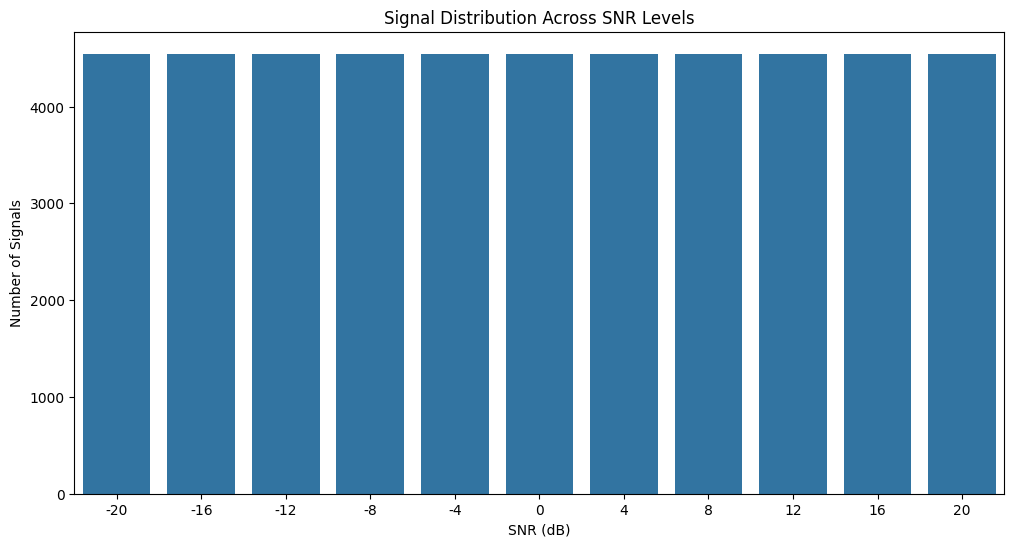

In [ ]:
# ==========================================
# SNR Distribution Plot
# ==========================================

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="SNR_dB"
)

plt.title("Signal Distribution Across SNR Levels")
plt.xlabel("SNR (dB)")
plt.ylabel("Number of Signals")

plt.show()

In [ ]:
# ==========================================
# Select One Signal
# ==========================================

sample = df[
    (df["Modulation"] == "BPSK") &
    (df["SNR_dB"] == -20)
].iloc[0]

I_signal = sample[[f"I_{i}" for i in range(1, 129)]].values
Q_signal = sample[[f"Q_{i}" for i in range(1, 129)]].values

print("Modulation:", sample["Modulation"])
print("SNR:", sample["SNR_dB"], "dB")
print("I samples:", len(I_signal))
print("Q samples:", len(Q_signal))

Modulation: BPSK
SNR: -20 dB
I samples: 128
Q samples: 128


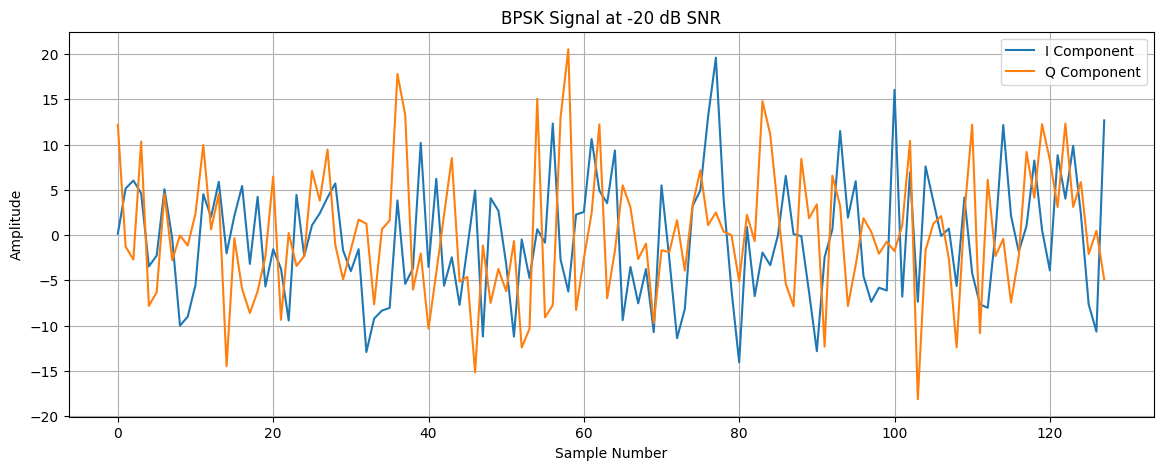

In [ ]:
# ==========================================
# Plot I/Q Signal
# ==========================================

plt.figure(figsize=(14, 5))

plt.plot(I_signal, label="I Component")
plt.plot(Q_signal, label="Q Component")

plt.title("BPSK Signal at -20 dB SNR")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")

plt.legend()
plt.grid()

plt.show()

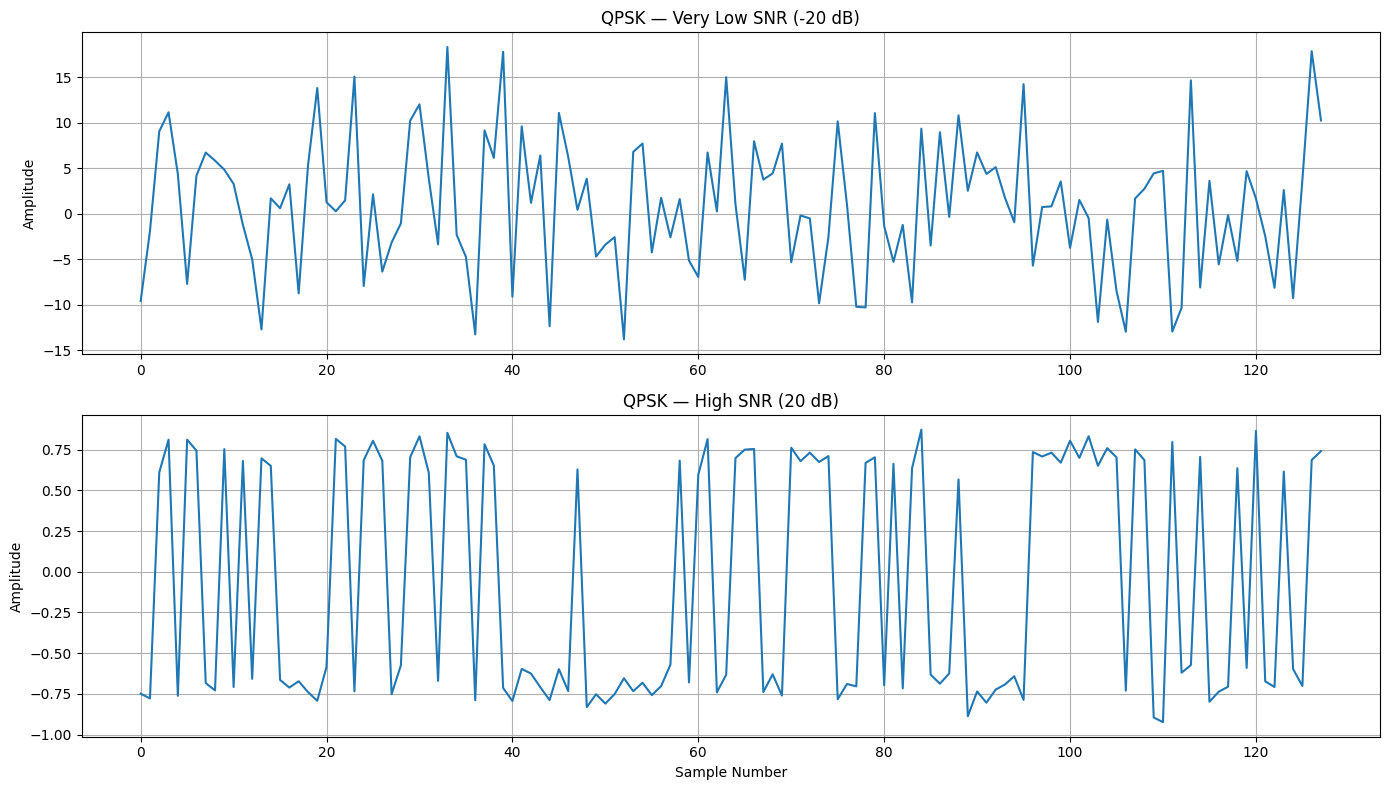

In [ ]:
# ==========================================
# Compare Low and High SNR
# ==========================================

low_snr = df[
    (df["Modulation"] == "QPSK") &
    (df["SNR_dB"] == -20)
].iloc[0]

high_snr = df[
    (df["Modulation"] == "QPSK") &
    (df["SNR_dB"] == 20)
].iloc[0]

low_I = low_snr[[f"I_{i}" for i in range(1,129)]].values
high_I = high_snr[[f"I_{i}" for i in range(1,129)]].values

plt.figure(figsize=(14, 8))

plt.subplot(2, 1, 1)
plt.plot(low_I)
plt.title("QPSK — Very Low SNR (-20 dB)")
plt.ylabel("Amplitude")
plt.grid()

plt.subplot(2, 1, 2)
plt.plot(high_I)
plt.title("QPSK — High SNR (20 dB)")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# STEP 11: PREPARE DATA FOR DEEP LEARNING
# ==========================================

# Get I and Q column names
I_columns = [f"I_{i}" for i in range(1, 129)]
Q_columns = [f"Q_{i}" for i in range(1, 129)]

# Extract I and Q values
I_data = df[I_columns].values
Q_data = df[Q_columns].values

print("I data shape:", I_data.shape)
print("Q data shape:", Q_data.shape)

# Combine I and Q
X = np.stack((I_data, Q_data), axis=2)

print("Final X shape:", X.shape)


I data shape: (50000, 128)
Q data shape: (50000, 128)
Final X shape: (50000, 128, 2)


In [ ]:
# ==========================================
# Encode Modulation Labels
# ==========================================

label_encoder = LabelEncoder()

y = label_encoder.fit_transform(df["Modulation"])

print("Classes:")
for i, class_name in enumerate(label_encoder.classes_):
    print(i, "=", class_name)

Classes:
0 = 16QAM
1 = 4ASK
2 = 64QAM
3 = 8PSK
4 = AM-DSB
5 = BPSK
6 = FM
7 = GMSK
8 = OOK
9 = QPSK


In [ ]:
# ==========================================
# Normalize I/Q Data
# ==========================================

mean = X.mean()
std = X.std()

X = (X - mean) / std

print("Mean after normalization:", X.mean())
print("Standard deviation:", X.std())

Mean after normalization: 1.4521717162097047e-18
Standard deviation: 1.0000000000000007


In [ ]:
# ==========================================
# TRAIN / VALIDATION / TEST SPLIT
# ==========================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

Training data: (35000, 128, 2)
Validation data: (7500, 128, 2)
Testing data: (7500, 128, 2)


In [ ]:
# ==========================================
# Check Class Distribution
# ==========================================

print("Training classes:")

unique, counts = np.unique(y_train, return_counts=True)

for class_id, count in zip(unique, counts):
    print(
        label_encoder.classes_[class_id],
        ":",
        count
    )

Training classes:
16QAM : 3500
4ASK : 3500
64QAM : 3500
8PSK : 3500
AM-DSB : 3500
BPSK : 3500
FM : 3500
GMSK : 3500
OOK : 3500
QPSK : 3500


In [ ]:
# ==========================================
# SAVE PROCESSED DATA
# ==========================================

np.savez_compressed(
    "processed_modulation_dataset.npz",
    X_train=X_train,
    X_val=X_val,
    X_test=X_test,
    y_train=y_train,
    y_val=y_val,
    y_test=y_test
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [ ]:
# ==========================================
# STEP 17: CNN MODEL
# ==========================================

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D,
    MaxPooling1D,
    BatchNormalization,
    Dropout,
    Flatten,
    Dense
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [ ]:
# ==========================================
# CNN ARCHITECTURE
# ==========================================

cnn_model = Sequential([

    # First convolution block
    Conv1D(
        filters=64,
        kernel_size=3,
        activation='relu',
        input_shape=(128, 2)
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    # Second convolution block
    Conv1D(
        filters=128,
        kernel_size=3,
        activation='relu'
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    # Third convolution block
    Conv1D(
        filters=256,
        kernel_size=3,
        activation='relu'
    ),

    BatchNormalization(),

    MaxPooling1D(pool_size=2),

    # Convert feature maps to vector
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    Dropout(0.5),

    # 10 modulation classes
    Dense(10, activation='softmax')
])

cnn_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 126, 64)        │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 63, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 61, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 28, 256)        │        98,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 256)        │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 14, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3584)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       458,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 585,674 (2.23 MB)

 Trainable params: 584,778 (2.23 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# ==========================================
# COMPILE CNN
# ==========================================

cnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN compiled successfully!")

CNN compiled successfully!


In [ ]:
# ==========================================
# TRAIN CNN
# ==========================================

history_cnn = cnn_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=15,

    batch_size=128,

    verbose=1
)

Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 48s 165ms/step - accuracy: 0.4478 - loss: 1.3975 - val_accuracy: 0.4057 - val_loss: 3.3110
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 82s 166ms/step - accuracy: 0.5123 - loss: 1.1644 - val_accuracy: 0.4879 - val_loss: 1.2792
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 81s 162ms/step - accuracy: 0.5613 - loss: 1.0682 - val_accuracy: 0.5587 - val_loss: 1.0473
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 83s 164ms/step - accuracy: 0.5852 - loss: 1.0203 - val_accuracy: 0.5953 - val_loss: 0.9864
Epoch 5/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 82s 165ms/step - accuracy: 0.5985 - loss: 0.9786 - val_accuracy: 0.6001 - val_loss: 0.9730
Epoch 6/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 81s 164ms/step - accuracy: 0.6115 - loss: 0.9485 - val_accuracy: 0.5927 - val_loss: 0.9937
Epoch 7/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 45s 164ms/step - accuracy: 0.6243 - loss: 0.9178 - val_accuracy: 0.5856 - val_loss: 1.0572
Epoch 8/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 46s 166ms/step - accuracy: 0.6393 - loss: 0

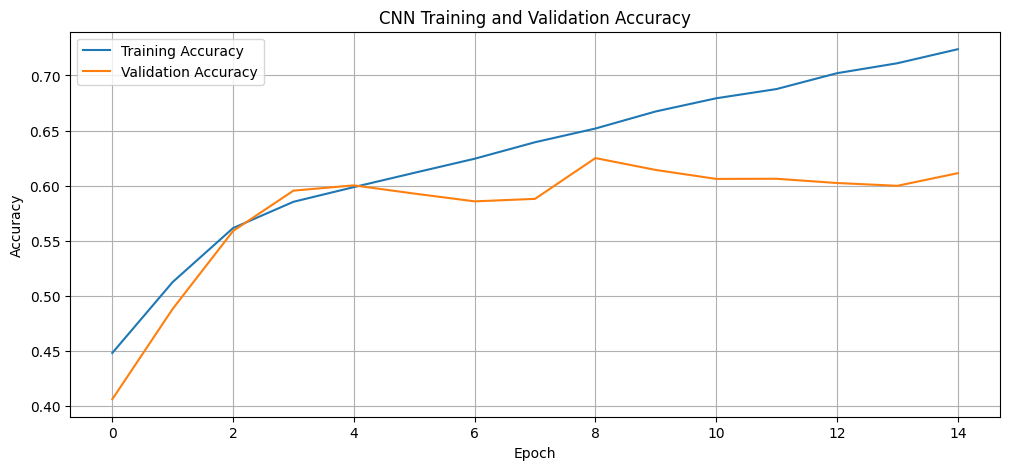

In [ ]:
# ==========================================
# CNN TRAINING HISTORY
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    history_cnn.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_cnn.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("CNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

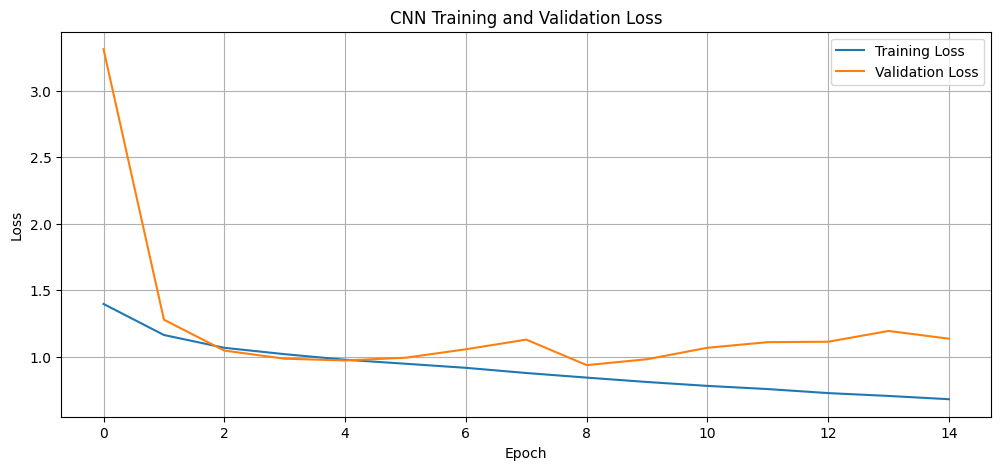

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    history_cnn.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_cnn.history['val_loss'],
    label='Validation Loss'
)

plt.title("CNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

In [ ]:
# ==========================================
# CNN TEST EVALUATION
# ==========================================

test_loss, test_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nCNN Test Accuracy:",
      round(test_accuracy * 100, 2), "%")

235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6053 - loss: 1.1902

CNN Test Accuracy: 60.53 %


In [ ]:
# ==========================================
# CLASSIFICATION REPORT
# ==========================================

y_pred_prob = cnn_model.predict(X_test)

y_pred = np.argmax(
    y_pred_prob,
    axis=1
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_encoder.classes_
    )
)

235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
              precision    recall  f1-score   support

       16QAM       0.29      0.32      0.30       750
        4ASK       0.64      0.61      0.62       750
       64QAM       0.33      0.31      0.32       750
        8PSK       0.40      0.52      0.45       750
      AM-DSB       0.88      0.87      0.87       750
        BPSK       0.80      0.57      0.66       750
          FM       0.84      0.92      0.88       750
        GMSK       0.57      0.73      0.64       750
         OOK       0.87      0.84      0.85       750
        QPSK       0.56      0.36      0.44       750

    accuracy                           0.61      7500
   macro avg       0.62      0.61      0.60      7500
weighted avg       0.62      0.61      0.60      7500



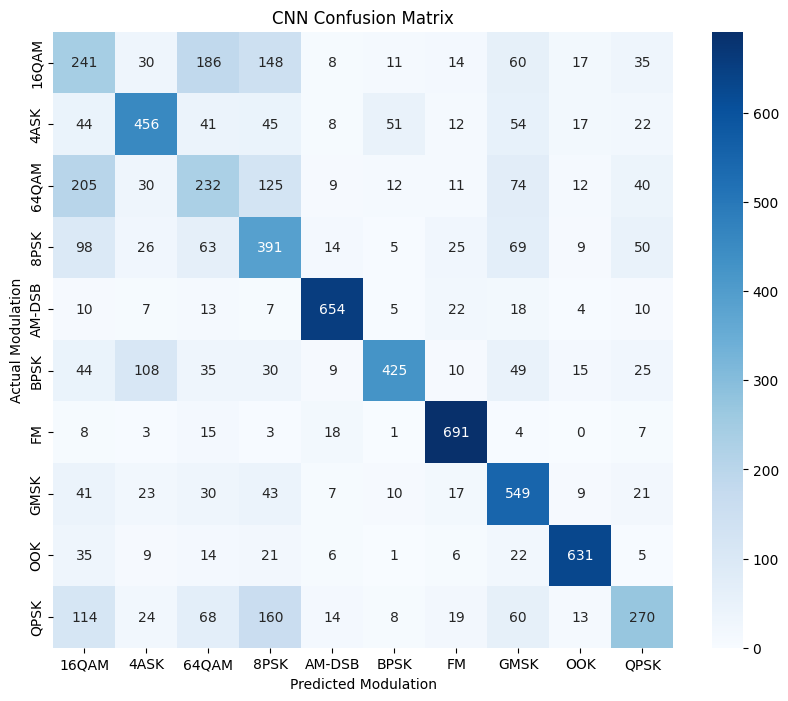

In [ ]:
# ==========================================
# CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Modulation")
plt.ylabel("Actual Modulation")

plt.show()

In [ ]:
# ==========================================
# STEP 28: LSTM MODEL
# ==========================================

from tensorflow.keras.layers import LSTM

lstm_model = Sequential([

    # LSTM learns sequential relationships
    LSTM(
        128,
        input_shape=(128, 2),
        return_sequences=True
    ),

    Dropout(0.3),

    LSTM(
        64,
        return_sequences=False
    ),

    Dropout(0.3),

    # Fully connected layer
    Dense(128, activation='relu'),

    Dropout(0.5),

    # 10 modulation classes
    Dense(10, activation='softmax')
])

lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 128, 128)       │        67,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,090 (492.54 KB)

 Trainable params: 126,090 (492.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# COMPILE LSTM
# ==========================================

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("LSTM compiled successfully!")

LSTM compiled successfully!


In [ ]:
# ==========================================
# TRAIN LSTM
# ==========================================

history_lstm = lstm_model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=15,

    batch_size=128,

    verbose=1
)

Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 172s 619ms/step - accuracy: 0.2757 - loss: 1.8996 - val_accuracy: 0.3432 - val_loss: 1.6000
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 201s 617ms/step - accuracy: 0.3493 - loss: 1.6154 - val_accuracy: 0.3580 - val_loss: 1.5634
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 167s 610ms/step - accuracy: 0.3523 - loss: 1.5794 - val_accuracy: 0.3685 - val_loss: 1.5337
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 203s 615ms/step - accuracy: 0.3611 - loss: 1.5648 - val_accuracy: 0.3672 - val_loss: 1.5286
Epoch 5/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 211s 648ms/step - accuracy: 0.3582 - loss: 1.5660 - val_accuracy: 0.3685 - val_loss: 1.5198
Epoch 6/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 193s 614ms/step - accuracy: 0.3594 - loss: 1.5505 - val_accuracy: 0.3708 - val_loss: 1.5178
Epoch 7/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 167s 610ms/step - accuracy: 0.3673 - loss: 1.5399 - val_accuracy: 0.3720 - val_loss: 1.5224
Epoch 8/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 169s 617ms/step - accuracy: 0.3633 -

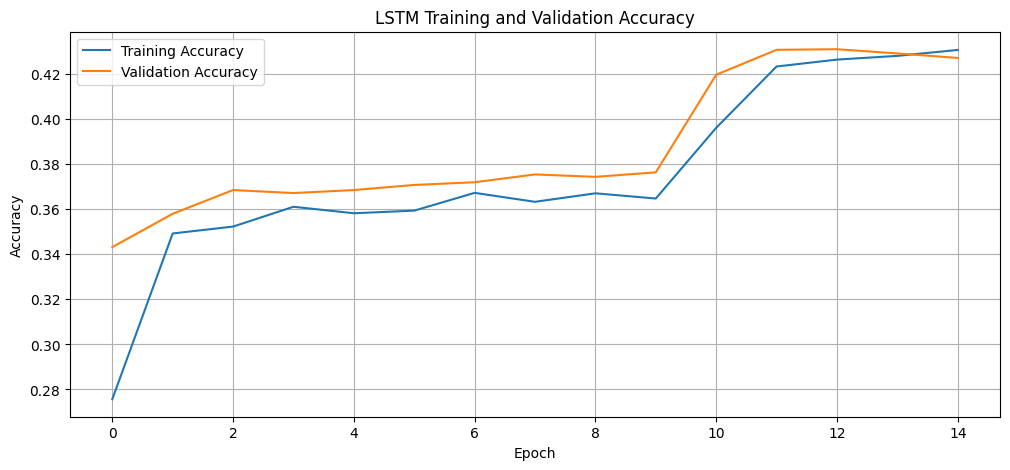

In [ ]:
# ==========================================
# LSTM ACCURACY
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    history_lstm.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history_lstm.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()

plt.show()

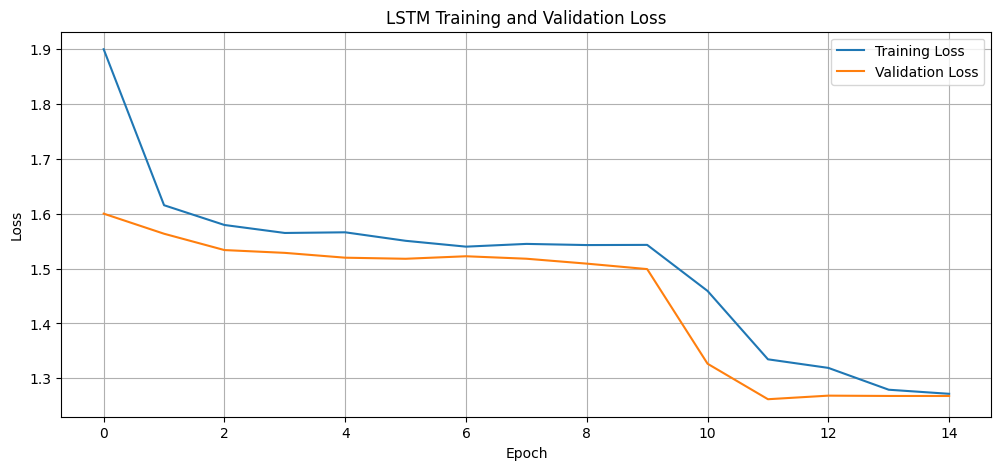

In [ ]:
# ==========================================
# LSTM LOSS
# ==========================================

plt.figure(figsize=(12, 5))

plt.plot(
    history_lstm.history['loss'],
    label='Training Loss'
)

plt.plot(
    history_lstm.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

In [ ]:
# ==========================================
# LSTM TEST EVALUATION
# ==========================================

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(
    "\nLSTM Test Accuracy:",
    round(lstm_accuracy * 100, 2),
    "%"
)

235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step - accuracy: 0.4252 - loss: 1.2925

LSTM Test Accuracy: 42.52 %


In [ ]:
# ==========================================
# LSTM CLASSIFICATION REPORT
# ==========================================

lstm_pred_prob = lstm_model.predict(X_test)

lstm_pred = np.argmax(
    lstm_pred_prob,
    axis=1
)

print(
    classification_report(
        y_test,
        lstm_pred,
        target_names=label_encoder.classes_
    )
)

235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step
              precision    recall  f1-score   support

       16QAM       0.15      0.15      0.15       750
        4ASK       0.00      0.00      0.00       750
       64QAM       0.07      0.00      0.01       750
        8PSK       0.11      0.04      0.06       750
      AM-DSB       0.64      0.93      0.76       750
        BPSK       0.42      0.75      0.54       750
          FM       0.92      0.85      0.88       750
        GMSK       0.14      0.01      0.02       750
         OOK       0.82      0.87      0.85       750
        QPSK       0.20      0.66      0.30       750

    accuracy                           0.43      7500
   macro avg       0.35      0.43      0.36      7500
weighted avg       0.35      0.43      0.36      7500



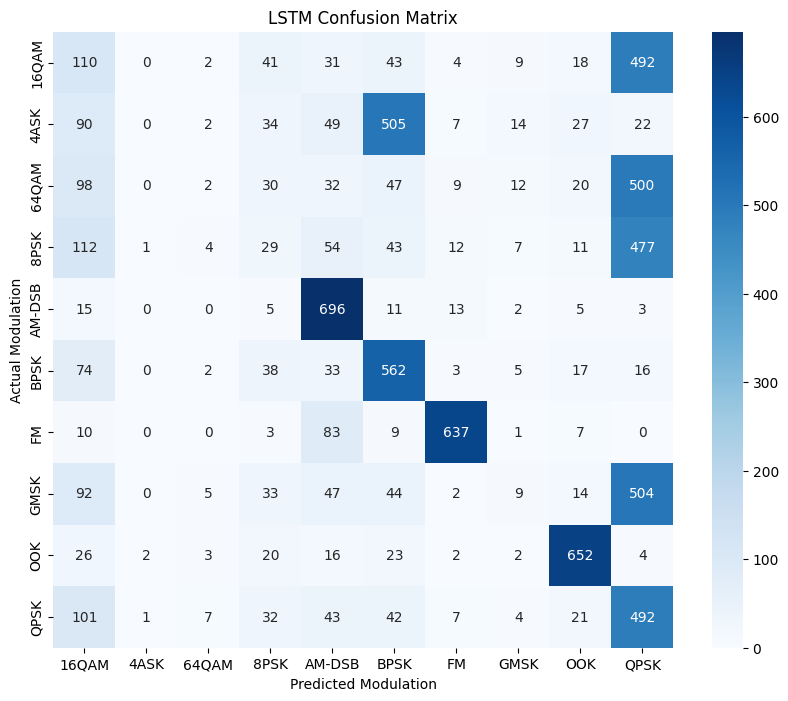

In [ ]:
# ==========================================
# LSTM CONFUSION MATRIX
# ==========================================

cm_lstm = confusion_matrix(
    y_test,
    lstm_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_lstm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Modulation")
plt.ylabel("Actual Modulation")

plt.show()

In [ ]:
# ==========================================
# RESTORE CNN AND LSTM ACCURACY VALUES
# ==========================================

# Evaluate CNN again
cnn_loss, cnn_accuracy = cnn_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

# Evaluate LSTM again
lstm_loss, lstm_accuracy = lstm_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("CNN Accuracy :", round(cnn_accuracy * 100, 2), "%")
print("LSTM Accuracy:", round(lstm_accuracy * 100, 2), "%")

235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.6053 - loss: 1.1902
235/235 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step - accuracy: 0.4252 - loss: 1.2925
CNN Accuracy : 60.53 %
LSTM Accuracy: 42.52 %


In [ ]:
# ==========================================
# CNN vs LSTM COMPARISON
# ==========================================

comparison = pd.DataFrame({
    "Model": [
        "CNN",
        "LSTM"
    ],

    "Test Accuracy": [
        cnn_accuracy,
        lstm_accuracy
    ]
})

comparison["Accuracy (%)"] = (
    comparison["Test Accuracy"] * 100
)

print("=" * 50)
print("       CNN vs LSTM PERFORMANCE")
print("=" * 50)

display(comparison)

       CNN vs LSTM PERFORMANCE


,Model,Test Accuracy,Accuracy (%)
0,CNN,0.605333,60.533333
1,LSTM,0.425200,42.519999


In [ ]:
# ==========================================
# CNN vs LSTM F1-SCORE
# ==========================================

from sklearn.metrics import f1_score

# CNN predictions
cnn_pred_prob = cnn_model.predict(
    X_test,
    verbose=0
)

cnn_pred_classes = np.argmax(
    cnn_pred_prob,
    axis=1
)

# LSTM predictions
lstm_pred_prob = lstm_model.predict(
    X_test,
    verbose=0
)

lstm_pred = np.argmax(
    lstm_pred_prob,
    axis=1
)

# F1 scores
cnn_f1 = f1_score(
    y_test,
    cnn_pred_classes,
    average="weighted"
)

lstm_f1 = f1_score(
    y_test,
    lstm_pred,
    average="weighted"
)

# Final comparison table
comparison = pd.DataFrame({
    "Model": ["CNN", "LSTM"],
    "Accuracy (%)": [
        cnn_accuracy * 100,
        lstm_accuracy * 100
    ],
    "Weighted F1": [
        cnn_f1,
        lstm_f1
    ]
})

display(comparison)

,Model,Accuracy (%),Weighted F1
0,CNN,60.533333,0.604861
1,LSTM,42.519999,0.356141


In [ ]:
# ==========================================
# STEP 37: CNN-LSTM HYBRID MODEL
# CORRECTED VERSION
# ==========================================

import tensorflow as tf

from tensorflow.keras.layers import (
    Input,
    Conv1D,
    MaxPooling1D,
    BatchNormalization,
    LSTM,
    Dense,
    Dropout,
    Concatenate,
    Flatten
)

from tensorflow.keras.models import Model


# ==========================================
# INPUT
# ==========================================

inputs = Input(shape=(128, 2))


# ==========================================
# CNN BRANCH
# ==========================================

cnn = Conv1D(
    64,
    3,
    activation='relu'
)(inputs)

cnn = BatchNormalization()(cnn)

cnn = MaxPooling1D(2)(cnn)

cnn = Conv1D(
    128,
    3,
    activation='relu'
)(cnn)

cnn = BatchNormalization()(cnn)

cnn = MaxPooling1D(2)(cnn)

cnn = Flatten()(cnn)


# ==========================================
# LSTM BRANCH
# ==========================================

lstm = LSTM(
    128,
    return_sequences=True
)(inputs)

lstm = Dropout(0.3)(lstm)

lstm = LSTM(
    64,
    return_sequences=False
)(lstm)

lstm = Dropout(0.3)(lstm)


# ==========================================
# COMBINE CNN + LSTM
# ==========================================

combined = Concatenate()([
    cnn,
    lstm
])


# ==========================================
# CLASSIFICATION
# ==========================================

x = Dense(
    128,
    activation='relu'
)(combined)

x = Dropout(0.5)(x)

outputs = Dense(
    10,
    activation='softmax'
)(x)


# ==========================================
# CREATE MODEL
# ==========================================

hybrid_model = Model(
    inputs=inputs,
    outputs=outputs
)


hybrid_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 128, 2)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 126, 64)   │        448 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 126, 64)   │        256 │ conv1d_5[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_5     │ (None, 63, 64)    │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_6 (Conv1D)   │ (None, 61, 128)   │     24,704 │ max_pooling1d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_5 (LSTM)       │ (None, 128, 128)  │     67,072 │ input_layer_3[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 61, 128)   │        512 │ conv1d_6[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128, 128)  │          0 │ lstm_5[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling1d_6     │ (None, 30, 128)   │          0 │ batch_normalizat… │
│ (MaxPooling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_6 (LSTM)       │ (None, 64)        │     49,408 │ dropout_7[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 3840)      │          0 │ max_pooling1d_6[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 64)        │          0 │ lstm_6[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3904)      │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ dropout_8[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 128)       │    499,840 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 128)       │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 10)        │      1,290 │ dropout_9[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 643,530 (2.45 MB)

 Trainable params: 643,146 (2.45 MB)

 Non-trainable params: 384 (1.50 KB)

In [ ]:
# ==========================================
# STEP 38: COMPILE CNN-LSTM HYBRID
# ==========================================

hybrid_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN-LSTM Hybrid model compiled successfully!")

CNN-LSTM Hybrid model compiled successfully!


In [ ]:
# ==========================================
# STEP 39: TRAIN CNN-LSTM HYBRID
# ==========================================

history_hybrid = hybrid_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=128,
    verbose=1
)

Epoch 1/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 207s 734ms/step - accuracy: 0.4401 - loss: 1.4507 - val_accuracy: 0.3909 - val_loss: 2.5236
Epoch 2/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 190s 695ms/step - accuracy: 0.4918 - loss: 1.1731 - val_accuracy: 0.4827 - val_loss: 1.1479
Epoch 3/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 207s 714ms/step - accuracy: 0.5086 - loss: 1.1383 - val_accuracy: 0.4920 - val_loss: 1.1360
Epoch 4/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 192s 702ms/step - accuracy: 0.5373 - loss: 1.0927 - val_accuracy: 0.4997 - val_loss: 1.1442
Epoch 5/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 201s 736ms/step - accuracy: 0.5784 - loss: 1.0280 - val_accuracy: 0.5277 - val_loss: 1.1556
Epoch 6/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 192s 702ms/step - accuracy: 0.6047 - loss: 0.9705 - val_accuracy: 0.5748 - val_loss: 1.0243
Epoch 7/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 210s 731ms/step - accuracy: 0.6293 - loss: 0.9093 - val_accuracy: 0.5968 - val_loss: 0.9888
Epoch 8/15
274/274 ━━━━━━━━━━━━━━━━━━━━ 193s 704ms/step - accuracy: 0.6523 -

In [ ]:
# Step 40: Evaluate CNN-LSTM Hybrid Model on Test Data

hybrid_loss, hybrid_accuracy = hybrid_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\nCNN-LSTM Hybrid Test Accuracy:",
      round(hybrid_accuracy * 100, 2), "%")

print("CNN-LSTM Hybrid Test Loss:",
      round(hybrid_loss, 4))

235/235 ━━━━━━━━━━━━━━━━━━━━ 24s 103ms/step - accuracy: 0.5904 - loss: 1.1226

CNN-LSTM Hybrid Test Accuracy: 59.04 %
CNN-LSTM Hybrid Test Loss: 1.1226


In [ ]:
from sklearn.metrics import classification_report
import numpy as np

# Get predictions
hybrid_pred_prob = hybrid_model.predict(X_test, verbose=1)

# Convert probabilities to class labels
hybrid_pred = np.argmax(hybrid_pred_prob, axis=1)

# Classification report
print("CNN-LSTM Hybrid Classification Report:\n")

print(
    classification_report(
        y_test,
        hybrid_pred,
        target_names=label_encoder.classes_
    )
)


235/235 ━━━━━━━━━━━━━━━━━━━━ 27s 113ms/step
CNN-LSTM Hybrid Classification Report:

              precision    recall  f1-score   support

       16QAM       0.29      0.27      0.28       750
        4ASK       0.65      0.51      0.57       750
       64QAM       0.25      0.28      0.27       750
        8PSK       0.63      0.39      0.49       750
      AM-DSB       0.93      0.83      0.88       750
        BPSK       0.58      0.68      0.63       750
          FM       0.89      0.89      0.89       750
        GMSK       0.49      0.70      0.58       750
         OOK       0.89      0.81      0.85       750
        QPSK       0.47      0.54      0.50       750

    accuracy                           0.59      7500
   macro avg       0.61      0.59      0.59      7500
weighted avg       0.61      0.59      0.59      7500



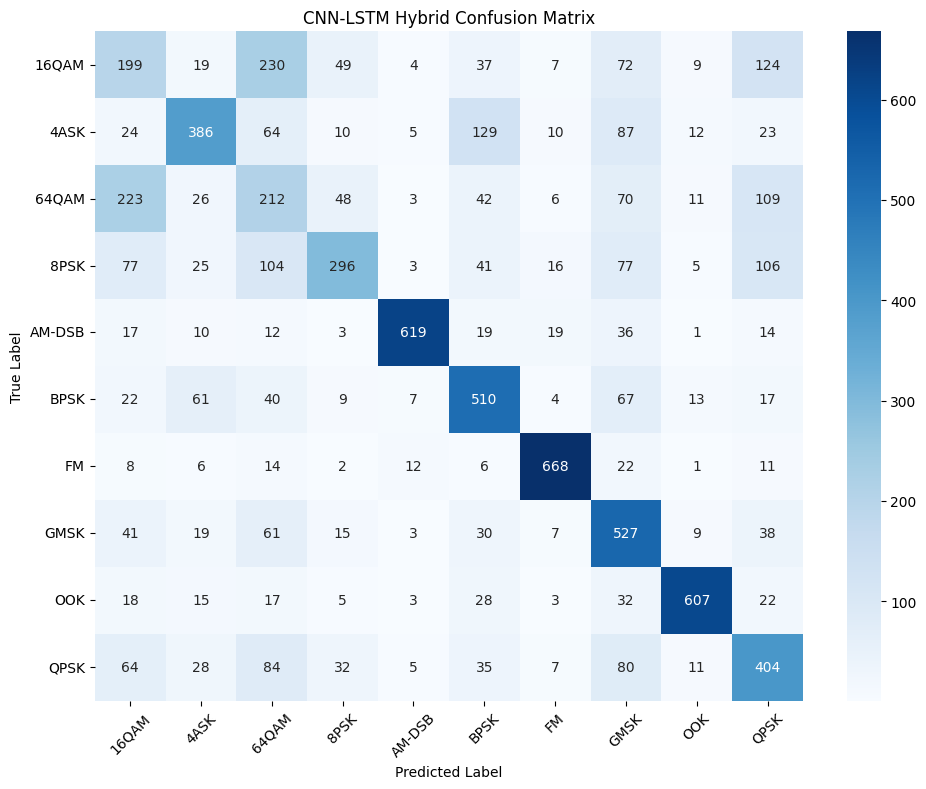

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix
cm_hybrid = confusion_matrix(y_test, hybrid_pred)

# Plot
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm_hybrid,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN-LSTM Hybrid Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print(df.columns.tolist())

['Signal_ID', 'Modulation', 'SNR_dB', 'I_1', 'I_2', 'I_3', 'I_4', 'I_5', 'I_6', 'I_7', 'I_8', 'I_9', 'I_10', 'I_11', 'I_12', 'I_13', 'I_14', 'I_15', 'I_16', 'I_17', 'I_18', 'I_19', 'I_20', 'I_21', 'I_22', 'I_23', 'I_24', 'I_25', 'I_26', 'I_27', 'I_28', 'I_29', 'I_30', 'I_31', 'I_32', 'I_33', 'I_34', 'I_35', 'I_36', 'I_37', 'I_38', 'I_39', 'I_40', 'I_41', 'I_42', 'I_43', 'I_44', 'I_45', 'I_46', 'I_47', 'I_48', 'I_49', 'I_50', 'I_51', 'I_52', 'I_53', 'I_54', 'I_55', 'I_56', 'I_57', 'I_58', 'I_59', 'I_60', 'I_61', 'I_62', 'I_63', 'I_64', 'I_65', 'I_66', 'I_67', 'I_68', 'I_69', 'I_70', 'I_71', 'I_72', 'I_73', 'I_74', 'I_75', 'I_76', 'I_77', 'I_78', 'I_79', 'I_80', 'I_81', 'I_82', 'I_83', 'I_84', 'I_85', 'I_86', 'I_87', 'I_88', 'I_89', 'I_90', 'I_91', 'I_92', 'I_93', 'I_94', 'I_95', 'I_96', 'I_97', 'I_98', 'I_99', 'I_100', 'I_101', 'I_102', 'I_103', 'I_104', 'I_105', 'I_106', 'I_107', 'I_108', 'I_109', 'I_110', 'I_111', 'I_112', 'I_113', 'I_114', 'I_115', 'I_116', 'I_117', 'I_118', 'I_119',

In [ ]:
from sklearn.model_selection import train_test_split
import numpy as np

# Get SNR values
snr_values = df["SNR_dB"].values

# Recreate the same split used earlier
_, snr_test = train_test_split(
    snr_values,
    test_size=0.15,
    random_state=42,
    stratify=label_encoder.transform(df["Modulation"])
)

print("SNR test shape:", snr_test.shape)
print("Unique SNR values:", np.sort(np.unique(snr_test)))

SNR test shape: (7500,)
Unique SNR values: [-20 -16 -12  -8  -4   0   4   8  12  16  20]


In [ ]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# Get predictions from all three trained models
# --------------------------------------------------

cnn_prob = cnn_model.predict(X_test, verbose=1)
cnn_pred = np.argmax(cnn_prob, axis=1)

lstm_prob = lstm_model.predict(X_test, verbose=1)
lstm_pred = np.argmax(lstm_prob, axis=1)

hybrid_prob = hybrid_model.predict(X_test, verbose=1)
hybrid_pred = np.argmax(hybrid_prob, axis=1)


# --------------------------------------------------
# Calculate accuracy for each SNR level
# --------------------------------------------------

snr_levels = np.sort(np.unique(snr_test))

snr_results = []

for snr in snr_levels:

    # Find test samples belonging to this SNR
    indices = np.where(snr_test == snr)[0]

    # True labels
    true_labels = y_test[indices]

    # Predictions
    cnn_labels = cnn_pred[indices]
    lstm_labels = lstm_pred[indices]
    hybrid_labels = hybrid_pred[indices]

    # Accuracy
    cnn_acc = np.mean(cnn_labels == true_labels)
    lstm_acc = np.mean(lstm_labels == true_labels)
    hybrid_acc = np.mean(hybrid_labels == true_labels)

    snr_results.append({
        "SNR (dB)": snr,
        "Samples": len(indices),
        "CNN Accuracy (%)": cnn_acc * 100,
        "LSTM Accuracy (%)": lstm_acc * 100,
        "CNN-LSTM Accuracy (%)": hybrid_acc * 100
    })


# --------------------------------------------------
# Create table
# --------------------------------------------------

snr_results_df = pd.DataFrame(snr_results)

print("\nSNR-Wise Model Performance:\n")

display(
    snr_results_df.round(2)
)

235/235 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step
235/235 ━━━━━━━━━━━━━━━━━━━━ 31s 133ms/step
235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 80ms/step

SNR-Wise Model Performance:



,SNR (dB),Samples,CNN Accuracy (%),LSTM Accuracy (%),CNN-LSTM Accuracy (%)
0,-20,694,58.36,39.77,56.77
1,-16,680,60.59,38.38,57.21
2,-12,714,60.78,43.70,56.44
3,-8,674,61.72,44.51,61.13
4,-4,669,61.58,42.30,59.04
5,0,670,60.30,44.78,61.64
6,4,695,60.43,41.29,58.42
7,8,676,61.83,44.08,59.02
8,12,685,61.61,44.09,60.58
9,16,660,57.73,44.39,59.85


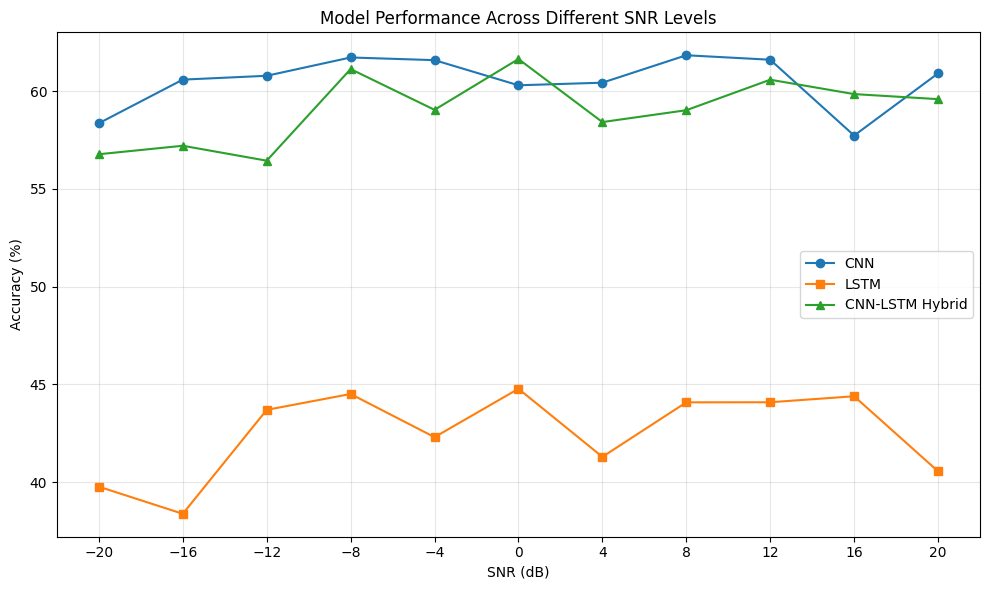

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    snr_results_df["SNR (dB)"],
    snr_results_df["CNN Accuracy (%)"],
    marker='o',
    label="CNN"
)

plt.plot(
    snr_results_df["SNR (dB)"],
    snr_results_df["LSTM Accuracy (%)"],
    marker='s',
    label="LSTM"
)

plt.plot(
    snr_results_df["SNR (dB)"],
    snr_results_df["CNN-LSTM Accuracy (%)"],
    marker='^',
    label="CNN-LSTM Hybrid"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Accuracy (%)")
plt.title("Model Performance Across Different SNR Levels")

plt.xticks(snr_results_df["SNR (dB)"])

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

# Overall accuracy
cnn_acc = accuracy_score(y_test, cnn_pred)
lstm_acc = accuracy_score(y_test, lstm_pred)
hybrid_acc = accuracy_score(y_test, hybrid_pred)

# Macro F1
cnn_macro_f1 = f1_score(y_test, cnn_pred, average='macro')
lstm_macro_f1 = f1_score(y_test, lstm_pred, average='macro')
hybrid_macro_f1 = f1_score(y_test, hybrid_pred, average='macro')

# Weighted F1
cnn_weighted_f1 = f1_score(y_test, cnn_pred, average='weighted')
lstm_weighted_f1 = f1_score(y_test, lstm_pred, average='weighted')
hybrid_weighted_f1 = f1_score(y_test, hybrid_pred, average='weighted')


# Create comparison table
final_comparison = pd.DataFrame({
    "Model": ["CNN", "LSTM", "CNN-LSTM Hybrid"],
    "Accuracy (%)": [
        cnn_acc * 100,
        lstm_acc * 100,
        hybrid_acc * 100
    ],
    "Macro F1": [
        cnn_macro_f1,
        lstm_macro_f1,
        hybrid_macro_f1
    ],
    "Weighted F1": [
        cnn_weighted_f1,
        lstm_weighted_f1,
        hybrid_weighted_f1
    ]
})

print("Final Model Comparison:\n")

display(final_comparison.round(4))

Final Model Comparison:



,Model,Accuracy (%),Macro F1,Weighted F1
0,CNN,60.5333,0.6049,0.6049
1,LSTM,42.5200,0.3561,0.3561
2,CNN-LSTM Hybrid,59.0400,0.5925,0.5925


In [ ]:
import numpy as np

# --------------------------------------------------
# Function to add AWGN noise
# --------------------------------------------------

def add_awgn_noise(X, snr_db):
    """
    Add Gaussian noise to I/Q signals.

    X      : input signals, shape (samples, 128, 2)
    snr_db : desired SNR in dB
    """

    signal_power = np.mean(X ** 2, axis=(1, 2), keepdims=True)

    snr_linear = 10 ** (snr_db / 10)

    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power) * np.random.normal(
        size=X.shape
    )

    return X + noise


# Reproducibility
np.random.seed(42)

# Create additional noisy test data
X_test_noisy_0db = add_awgn_noise(X_test, 0)

print("Original test shape :", X_test.shape)
print("Noisy test shape    :", X_test_noisy_0db.shape)

Original test shape : (7500, 128, 2)
Noisy test shape    : (7500, 128, 2)


In [ ]:
# --------------------------------------------------
# Evaluate CNN on noisy test data
# --------------------------------------------------

cnn_noisy_prob = cnn_model.predict(
    X_test_noisy_0db,
    verbose=1
)

cnn_noisy_pred = np.argmax(
    cnn_noisy_prob,
    axis=1
)

cnn_noisy_accuracy = np.mean(
    cnn_noisy_pred == y_test
)


# --------------------------------------------------
# Evaluate LSTM on noisy test data
# --------------------------------------------------

lstm_noisy_prob = lstm_model.predict(
    X_test_noisy_0db,
    verbose=1
)

lstm_noisy_pred = np.argmax(
    lstm_noisy_prob,
    axis=1
)

lstm_noisy_accuracy = np.mean(
    lstm_noisy_pred == y_test
)


# --------------------------------------------------
# Evaluate CNN-LSTM Hybrid on noisy test data
# --------------------------------------------------

hybrid_noisy_prob = hybrid_model.predict(
    X_test_noisy_0db,
    verbose=1
)

hybrid_noisy_pred = np.argmax(
    hybrid_noisy_prob,
    axis=1
)

hybrid_noisy_accuracy = np.mean(
    hybrid_noisy_pred == y_test
)


# --------------------------------------------------
# Display results
# --------------------------------------------------

print("\nAdditional 0 dB Noise Test Results")
print("----------------------------------")

print(
    "CNN Accuracy:",
    round(cnn_noisy_accuracy * 100, 2),
    "%"
)

print(
    "LSTM Accuracy:",
    round(lstm_noisy_accuracy * 100, 2),
    "%"
)

print(
    "CNN-LSTM Hybrid Accuracy:",
    round(hybrid_noisy_accuracy * 100, 2),
    "%"
)

235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step
235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step
235/235 ━━━━━━━━━━━━━━━━━━━━ 19s 81ms/step

Additional 0 dB Noise Test Results
----------------------------------
CNN Accuracy: 46.45 %
LSTM Accuracy: 39.4 %
CNN-LSTM Hybrid Accuracy: 45.04 %


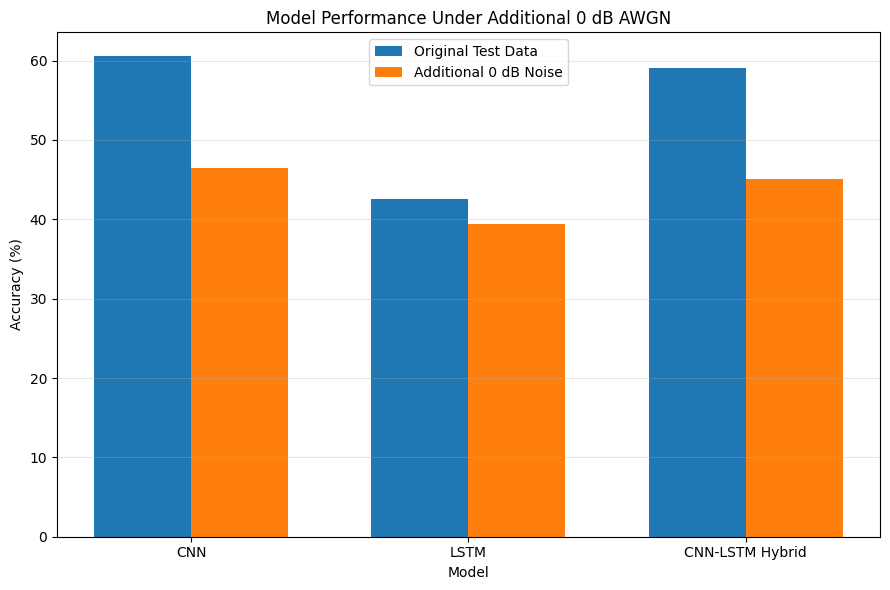

In [ ]:
import matplotlib.pyplot as plt

models = ["CNN", "LSTM", "CNN-LSTM Hybrid"]

original_accuracy = [
    60.53,
    42.52,
    59.04
]

noisy_accuracy = [
    cnn_noisy_accuracy * 100,
    lstm_noisy_accuracy * 100,
    hybrid_noisy_accuracy * 100
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width/2,
    original_accuracy,
    width,
    label="Original Test Data"
)

plt.bar(
    x + width/2,
    noisy_accuracy,
    width,
    label="Additional 0 dB Noise"
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Model Performance Under Additional 0 dB AWGN")
plt.xticks(x, models)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [ ]:
# Step 51: Prepare data for SHAP

import shap
import numpy as np

# Use a small background dataset
background = X_train[:50]

# Select one test signal to explain
sample_index = 0
sample_to_explain = X_test[sample_index:sample_index + 1]

print("Background shape:", background.shape)
print("Sample shape:", sample_to_explain.shape)

# Check the true class
true_class = y_test[sample_index]

print("True class index:", true_class)
print("True modulation:", label_encoder.inverse_transform([true_class])[0])

Background shape: (50, 128, 2)
Sample shape: (1, 128, 2)
True class index: 6
True modulation: FM


In [ ]:
# Step 52: Create SHAP Explainer for CNN-LSTM Hybrid

import shap

print("Creating SHAP explainer...")

explainer = shap.Explainer(
    hybrid_model,
    background
)

print("SHAP explainer created successfully!")

Creating SHAP explainer...
SHAP explainer created successfully!


In [ ]:
# Step 53: Create a SHAP-compatible prediction function

import shap
import numpy as np

def hybrid_predict(X):
    """
    SHAP-compatible prediction function.
    Returns the 10-class probabilities from the CNN-LSTM model.
    """
    X = np.asarray(X, dtype=np.float32)
    return hybrid_model.predict(X, verbose=0)


# Create SHAP masker
masker = shap.maskers.Independent(background)

# Create the explainer
explainer = shap.Explainer(
    hybrid_predict,
    masker
)

print("SHAP explainer recreated successfully!")

SHAP explainer recreated successfully!


In [ ]:
# Step 54A: Flatten data only for SHAP

import numpy as np
import shap

# Flatten each signal:
# (128, 2) -> (256,)
background_flat = background.reshape(background.shape[0], -1)
sample_flat = sample_to_explain.reshape(1, -1)

print("Original background shape:", background.shape)
print("Flattened background shape:", background_flat.shape)

print("Original sample shape:", sample_to_explain.shape)
print("Flattened sample shape:", sample_flat.shape)

Original background shape: (50, 128, 2)
Flattened background shape: (50, 256)
Original sample shape: (1, 128, 2)
Flattened sample shape: (1, 256)


In [ ]:
# Step 54B: SHAP-compatible prediction function

def hybrid_predict_flat(X):
    """
    SHAP passes flattened signals of shape (samples, 256).
    Convert them back to (samples, 128, 2)
    before giving them to the CNN-LSTM model.
    """

    X = np.asarray(X, dtype=np.float32)

    X = X.reshape(-1, 128, 2)

    return hybrid_model.predict(X, verbose=0)


# Create a new SHAP masker using flattened data
masker = shap.maskers.Independent(background_flat)

# Create SHAP explainer
explainer = shap.Explainer(
    hybrid_predict_flat,
    masker
)

print("Flattened SHAP explainer created successfully!")

Flattened SHAP explainer created successfully!


In [ ]:
# Step 55: Generate SHAP explanation

print("Generating SHAP values...")

shap_values = explainer(
    sample_flat,
    max_evals=513
)

print("SHAP values generated successfully!")
print("SHAP values shape:", shap_values.values.shape)

Generating SHAP values...


PermutationExplainer explainer: 2it [01:13, 73.82s/it]               

SHAP values generated successfully!
SHAP values shape: (1, 256, 10)


In [ ]:
# Step 56: Find the model's prediction

pred_probs = hybrid_model.predict(sample_to_explain, verbose=0)[0]

predicted_class = np.argmax(pred_probs)
predicted_label = label_encoder.inverse_transform([predicted_class])[0]

true_class = y_test[sample_index]
true_label = label_encoder.inverse_transform([true_class])[0]

print("True class      :", true_class)
print("True modulation :", true_label)

print("\nPredicted class      :", predicted_class)
print("Predicted modulation :", predicted_label)

print("\nPrediction probabilities:")
for i, label in enumerate(label_encoder.classes_):
    print(f"{label:8s} : {pred_probs[i]:.4f}")

True class      : 6
True modulation : FM

Predicted class      : 6
Predicted modulation : FM

Prediction probabilities:
16QAM    : 0.0000
4ASK     : 0.0000
64QAM    : 0.0000
8PSK     : 0.0000
AM-DSB   : 0.0000
BPSK     : 0.0000
FM       : 1.0000
GMSK     : 0.0000
OOK      : 0.0000
QPSK     : 0.0000


In [ ]:
# Step 57: Extract SHAP values for the predicted class (FM)

# Predicted class is 6 = FM
shap_fm = shap_values.values[0, :, predicted_class]

print("SHAP FM values shape:", shap_fm.shape)

# Convert the 256 SHAP features back to I/Q format
shap_fm_2d = shap_fm.reshape(128, 2)

print("SHAP I/Q shape:", shap_fm_2d.shape)

print("\nFirst 10 SHAP values:")
print(shap_fm_2d[:10])

SHAP FM values shape: (256,)
SHAP I/Q shape: (128, 2)

First 10 SHAP values:
[[-2.28609896e-02 -3.21600845e-04]
 [-4.80962485e-03  6.22878825e-05]
 [-1.98105789e-04 -4.66592013e-02]
 [-1.85541856e-03 -9.52717232e-05]
 [-6.37125360e-04 -1.15524088e-03]
 [ 7.53770491e-03  4.95218874e-03]
 [-3.85890979e-03  2.04073503e-03]
 [ 2.14065023e-03 -1.38657777e-03]
 [ 1.32265337e-04  3.43152438e-04]
 [ 1.07970858e-03  1.34537278e-03]]


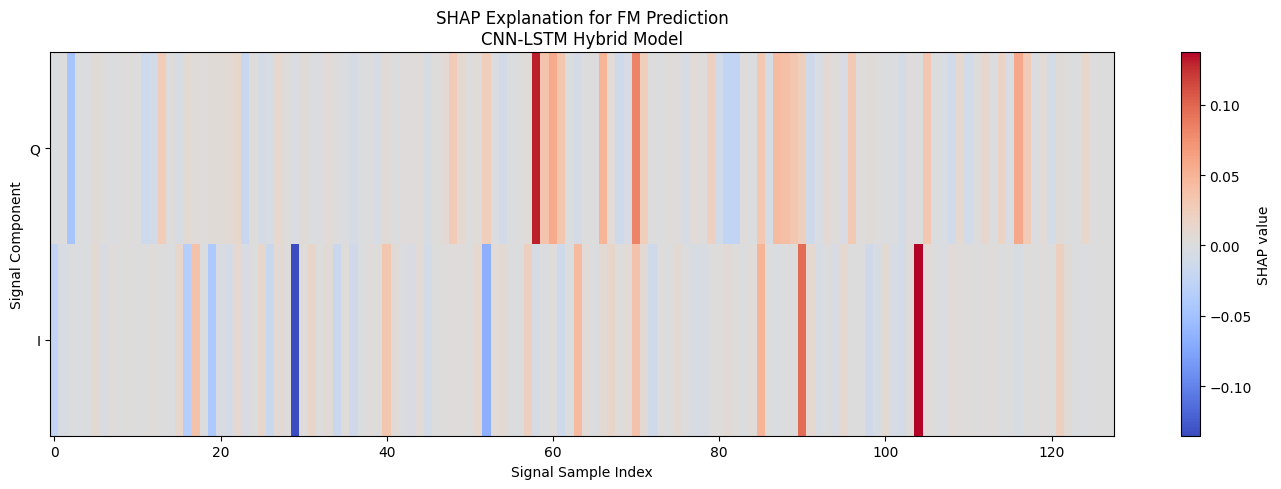

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Step 58: SHAP heatmap for FM prediction

plt.figure(figsize=(14, 5))

plt.imshow(
    shap_fm_2d.T,
    aspect='auto',
    cmap='coolwarm',
    origin='lower'
)

plt.colorbar(label='SHAP value')

plt.xlabel('Signal Sample Index')
plt.ylabel('Signal Component')
plt.yticks([0, 1], ['I', 'Q'])

plt.title(
    'SHAP Explanation for FM Prediction\n'
    'CNN-LSTM Hybrid Model'
)

plt.tight_layout()
plt.show()

In [ ]:
# Step 59: Find the most important signal positions

# Absolute SHAP value = importance
importance = np.abs(shap_fm_2d)

# Combine I and Q importance at each signal position
position_importance = importance.sum(axis=1)

# Get indices of top 10 positions
top_indices = np.argsort(position_importance)[-10:][::-1]

print("Top 10 most important signal positions for FM prediction:\n")

for rank, idx in enumerate(top_indices, start=1):
    print(
        f"{rank}. Position {idx + 1:3d} | "
        f"I SHAP = {shap_fm_2d[idx, 0]: .6f} | "
        f"Q SHAP = {shap_fm_2d[idx, 1]: .6f} | "
        f"Total Importance = {position_importance[idx]: .6f}"
    )

Top 10 most important signal positions for FM prediction:

1. Position  30 | I SHAP = -0.135272 | Q SHAP = -0.002955 | Total Importance =  0.138227
2. Position 105 | I SHAP =  0.137314 | Q SHAP =  0.000853 | Total Importance =  0.138167
3. Position  59 | I SHAP = -0.007249 | Q SHAP =  0.130540 | Total Importance =  0.137789
4. Position  91 | I SHAP =  0.095944 | Q SHAP =  0.023254 | Total Importance =  0.119199
5. Position  71 | I SHAP =  0.036196 | Q SHAP =  0.082250 | Total Importance =  0.118447
6. Position  53 | I SHAP = -0.066641 | Q SHAP =  0.023625 | Total Importance =  0.090266
7. Position  86 | I SHAP =  0.048337 | Q SHAP =  0.030701 | Total Importance =  0.079038
8. Position 117 | I SHAP = -0.004489 | Q SHAP =  0.058152 | Total Importance =  0.062640
9. Position  61 | I SHAP =  0.003365 | Q SHAP =  0.055720 | Total Importance =  0.059085
10. Position  67 | I SHAP =  0.006631 | Q SHAP =  0.048351 | Total Importance =  0.054982


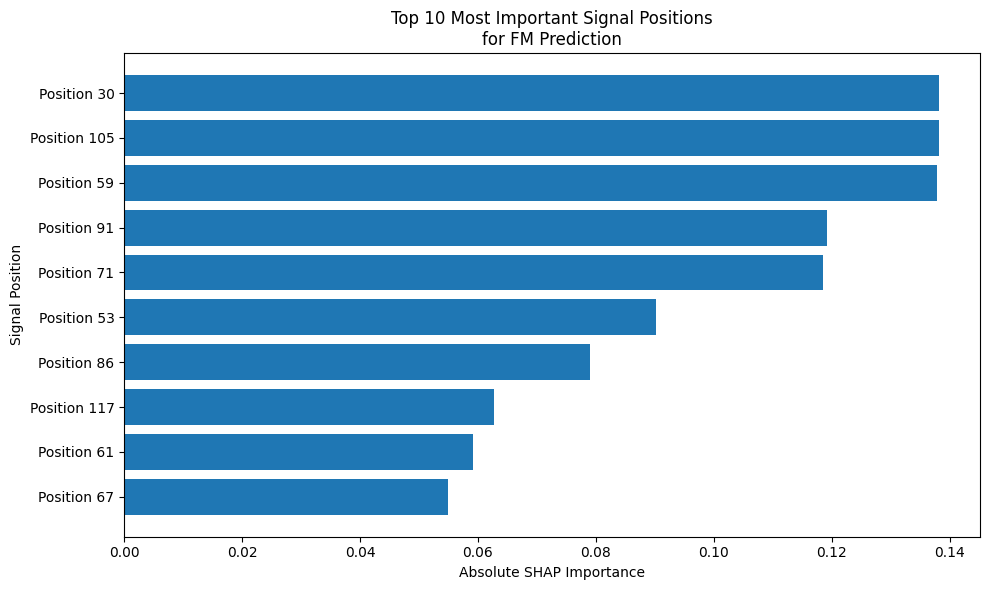

In [ ]:
# Step 60: Plot Top-10 SHAP important signal positions

import matplotlib.pyplot as plt

# Get importance values for the top 10 positions
top_positions = top_indices + 1
top_importance = position_importance[top_indices]

plt.figure(figsize=(10, 6))

plt.barh(
    range(len(top_positions)),
    top_importance[::-1]
)

plt.yticks(
    range(len(top_positions)),
    [f"Position {p}" for p in top_positions[::-1]]
)

plt.xlabel("Absolute SHAP Importance")
plt.ylabel("Signal Position")

plt.title(
    "Top 10 Most Important Signal Positions\n"
    "for FM Prediction"
)

plt.tight_layout()
plt.show()